# TG_NLDAS2_2000-2000_quicktest: first look at ELM output

Basic plots of the 5-day ELM test run over Tony Grove, UT (1–5 Jan 2000), made with
`run_scripts/testing/TG_NLDAS2_2000-2000_test.sh`.

**What's in the output.** The run script sets `hist_nhtfrq = -24, -1` and
`hist_mfilt = 365, 8760`, so ELM writes two history "tapes":

| tape | file | averaging | records |
|---|---|---|---|
| h0 | `*.elm.h0.2000-01-01-00000.nc` | daily mean (`-24` = every 24 h) | 1 initial + 5 days |
| h1 | `*.elm.h1.2000-01-01-00000.nc` | hourly mean (`-1` = every hour) | 1 initial + 120 hours |

Both tapes have the same fields (`hist_fincl1 = hist_fincl2`), on the 12 × 8
lat/lon grid of the TG domain (0.125°, the NLDAS2 grid). Field definitions are
in `components/elm/src/data_types/ColumnDataType.F90` (the `hist_addfld1d` calls);
`tools/list_hist_fields.py` lists them all.

**Two time-axis details** (worth knowing for any ELM/CLM history file):
1. The `time` value is the *end* of the averaging interval. A daily mean stamped
   `2000-01-02 00:00` is the average over 1 Jan. The `time_bounds` variable gives the
   interval, so this notebook re-stamps each record at the interval midpoint.
2. The first record of each tape is written at model step 0, before the model has
   run, and only covers half a time step (23:30–00:00 on 31 Dec). It's dropped below.

**Cold start.** The case has no initial-conditions file (`finidat`), so ELM starts
from its default cold-start state with no snow on the ground. In early January
Tony Grove normally has a deep snowpack, so the snow here is only what fell
during these 5 days. A real run needs a spinup first.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv

CASE = "TG_NLDAS2_2000-2000_quicktest"

# OUTPUT_ROOT comes from the .env file in the repo root (found by searching up from the
# notebook's working directory). Copy each new test run's history files to
# $OUTPUT_ROOT/<CASE>/, then re-run this notebook.
env_file = find_dotenv(usecwd=True)
if not env_file:
    raise FileNotFoundError("No .env file found in this directory or any parent")
load_dotenv(env_file, override=True)
if "OUTPUT_ROOT" not in os.environ:
    raise KeyError(f"OUTPUT_ROOT is not set in {env_file}")
DATA_DIR = Path(os.environ["OUTPUT_ROOT"]) / CASE
print(f"Reading {CASE} from {DATA_DIR}  (env: {env_file})")

# Tony Grove RS SNOTEL (site 823), Bear River Range, UT
SITE_NAME = "Tony Grove RS SNOTEL"
SITE_LAT, SITE_LON = 41.89, -111.57

# Colors: fixed order, so a variable keeps its color across figures
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # blue, orange, aqua
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "lines.linewidth": 1.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Reading TG_NLDAS2_2000-2000_quicktest from /home/chris/Science/data/E3SM/output/TG_NLDAS2_2000-2000_quicktest  (env: /home/chris/Science/coding/E3SM_run_scripts/.env)


## Load the data

`open_history` opens one tape, drops the step-0 record and moves the time stamps to
the interval midpoints. ELM uses a `noleap` (365-day) calendar, so xarray decodes
times as `cftime` objects; they are converted to ordinary `datetime64` here, which
is safe for these dates and makes plotting easier.

In [2]:
def open_history(tape):
    f = DATA_DIR / f"{CASE}.elm.{tape}.2000-01-01-00000.nc"
    ds = xr.open_dataset(f)
    ds = ds.isel(time=slice(1, None))            # drop the step-0 record
    t0, t1 = ds["time_bounds"].values.T          # cftime objects
    ds = ds.assign_coords(time=t0 + (t1 - t0) / 2)
    ds = ds.convert_calendar("standard", use_cftime=False)
    ds = ds.assign_coords(lon=((ds.lon + 180) % 360) - 180)   # 0..360 -> -180..180
    return ds

daily = open_history("h0")
hourly = open_history("h1")
print(f"daily:  {daily.sizes['time']} records, {daily.time.values[0]} .. {daily.time.values[-1]}")
print(f"hourly: {hourly.sizes['time']} records, {hourly.time.values[0]} .. {hourly.time.values[-1]}")
hourly

daily:  5 records, 2000-01-01T12:00:00.000000000 .. 2000-01-05T12:00:00.000000000
hourly: 120 records, 2000-01-01T00:30:00.000000000 .. 2000-01-05T23:30:00.000000000


<xarray.Dataset> Size: 842kB
Dimensions:       (time: 120, hist_interval: 2, lat: 12, lon: 8, levgrnd: 15,
                   levlak: 10, levdcmp: 15, levsoi: 10)
Coordinates:
  * time          (time) datetime64[ns] 960B 2000-01-01T00:30:00 ... 2000-01-...
  * lat           (lat) float32 48B 41.06 41.19 41.31 ... 42.19 42.31 42.44
  * lon           (lon) float32 32B -111.9 -111.8 -111.7 ... -111.2 -111.1
  * levgrnd       (levgrnd) float32 60B 0.007101 0.02792 0.06226 ... 21.33 35.18
  * levlak        (levlak) float32 40B 0.05 0.6 2.1 4.6 ... 25.6 34.33 44.78
  * levdcmp       (levdcmp) float32 60B 0.007101 0.02792 0.06226 ... 21.33 35.18
  * levsoi        (levsoi) float32 40B 0.007101 0.02792 0.06226 ... 1.728 2.865
Dimensions without coordinates: hist_interval
Data variables: (12/31)
    mcdate        (time) int32 480B ...
    mcsec         (time) int32 480B ...
    mdcur         (time) int32 480B ...
    mscur         (time) int32 480B ...
    nstep         (time) int32 480B ...
    time_bounds   (time, hist_interval) object 2kB 2000-01-01 00:00:00 ... 20...
    ...            ...
    SNOTTOPL      (time, lat, lon) float32 46kB ...
    SNOW          (time, lat, lon) float32 46kB ...
    SNOWDP        (time, lat, lon) float32 46kB ...
    SNOW_DEPTH    (time, lat, lon) float32 46kB ...
    TBOT          (time, lat, lon) float32 46kB ...
    TG            (time, lat, lon) float32 46kB ...
Attributes: (12/29)
    title:                                     ELM History file information
    source:                                    E3SM Land Model
    source_id:                                 fe85f116b9
    product:                                   model-output
    realm:                                     land
    case:                                      TG_NLDAS2_2000-2000_quicktest
    ...                                        ...
    ltype_wetland:                             6
    ltype_urban_tbd:                           7
    ltype_urban_hd:                            8
    ltype_urban_md:                            9
    Time_constant_3Dvars_filename:             ./TG_NLDAS2_2000-2000_quicktes...
    Time_constant_3Dvars:                      ZSOI:DZSOI:WATSAT:SUCSAT:BSW:H...

In [3]:
# The fields requested in the run script, with ELM's long names and units
fields = [v for v in hourly.data_vars if hourly[v].dims == ("time", "lat", "lon")]
for v in fields:
    print(f"{v:12s} {hourly[v].attrs.get('units', ''):8s} {hourly[v].attrs.get('long_name', '')}")

EFLX_LH_TOT  W/m^2    total latent heat flux [+ to atm]
FSA          W/m^2    absorbed solar radiation
FSDS         W/m^2    atmospheric incident solar radiation
FSH          W/m^2    sensible heat
FSNO         1        fraction of ground covered by snow
FSNO_EFF     1        effective fraction of ground covered by snow
FSR          W/m^2    reflected solar radiation
H2OSNO       mm       snow depth (liquid water)
QRUNOFF      mm/s     total liquid runoff (does not include QSNWCPICE)
QSNOMELT     mm/s     snow melt
RAIN         mm/s     atmospheric rain
SNORDSL      m^-6     top snow layer effective grain radius
SNOTTOPL     K        snow temperature (top layer)
SNOW         mm/s     atmospheric snow
SNOWDP       m        gridcell mean snow height
SNOW_DEPTH   m        snow height of snow covered area
TBOT         K        atmospheric air temperature
TG           K        ground temperature


### Unit conversions

ELM reports water fluxes (`SNOW`, `RAIN`, `QSNOMELT`, `QRUNOFF`) in mm/s, i.e. kg m⁻² s⁻¹.
Convert to mm/h for hourly data and mm/day for daily data. Temperatures are in K.

`SNORDSL` (top-layer snow grain radius) is labeled `m^-6` in the file, but the value is
in micrometres (μm). It and `SNOTTOPL` (top snow-layer temperature) are NaN when a
cell has no snow layers.

In [4]:
FLUXES = ["SNOW", "RAIN", "QSNOMELT", "QRUNOFF"]

def convert(ds, per):
    ds = ds.copy()
    secs = {"h": 3600, "day": 86400}[per]
    for v in FLUXES:
        ds[v] = (ds[v] * secs).assign_attrs(ds[v].attrs, units=f"mm/{per}")
    for v in ["TBOT", "TG", "SNOTTOPL"]:
        ds[v] = (ds[v] - 273.15).assign_attrs(ds[v].attrs, units="°C")
    ds["SNORDSL"] = ds["SNORDSL"].assign_attrs(units="μm")
    return ds

hourly = convert(hourly, "h")
daily = convert(daily, "day")

## The domain

All 96 cells are land (`landmask = 1`). The site's nearest cell is marked with a star.

Two fields copied from the domain file don't look right:
- `topo` is 0 everywhere. This is just the domain file's elevation field, which isn't
  set, so it is not the real terrain.
- `area` is about 634,000 km² per cell, but a 0.125° cell at 42°N is about 150 km².
  ELM reads the domain `area` in rad² and multiplies by Earth's radius squared:
  634,257 / 6371² ≈ 0.0156 ≈ 0.125², so the domain file seems to hold deg², not rad².
  `build_input_data/matlab_code/CreateELMUgridDomain.m` computes area as Δlon × Δlat
  in degrees. The snow physics doesn't use `area`, but area-weighted sums and the
  coupler's budgets do.

Nearest cell to Tony Grove RS SNOTEL: lat 41.9375, lon -111.5625
Cell area: 634256.9 km²


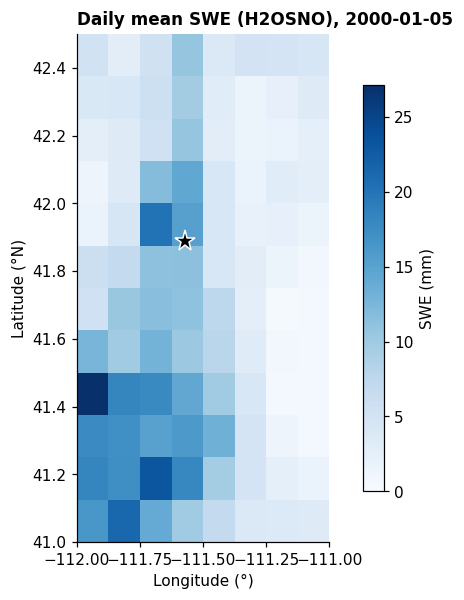

In [5]:
site = dict(lat=SITE_LAT, lon=SITE_LON)
site_cell = hourly.sel(site, method="nearest")
print(f"Nearest cell to {SITE_NAME}: lat {float(site_cell.lat):.4f}, lon {float(site_cell.lon):.4f}")
print(f"Cell area: {float(site_cell.area):.1f} km²")

fig, ax = plt.subplots(figsize=(8, 6))
swe_end = daily["H2OSNO"].isel(time=-1)
im = swe_end.plot(ax=ax, cmap="Blues", vmin=0, add_colorbar=False)
fig.colorbar(im, ax=ax, label="SWE (mm)", shrink=0.8)
ax.plot(SITE_LON, SITE_LAT, marker="*", ms=14, color="k", mec="w", mew=1)
ax.set_title(f"Daily mean SWE (H2OSNO), {str(swe_end.time.values)[:10]}")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°N)")
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.set_aspect(1 / np.cos(np.deg2rad(SITE_LAT)))
ax.grid(False)

## Calculate using offline package

In [6]:
# Tony Grove cell as pandas DataFrames, with columns named the way the fsca package
# expects them (see fsca.point_calc.calc_point_fsca): SWE in mm, DEPTH in m, and a
# DatetimeIndex. The other columns keep their ELM names, in the units set above
# (fluxes in mm/h or mm/day, temperatures in °C).
#   SWE   = H2OSNO (cell-mean snow water equivalent)
#   DEPTH = SNOWDP (cell-mean snow depth; SNOW_DEPTH is depth over the snow-covered part)
#   FSNO  = ELM's fSCA from snow_fsca_param = 'SL12', for comparison
TG_COLS = ["H2OSNO", "SNOWDP", "SNOW_DEPTH", "FSNO", "FSNO_EFF", "SNOW", "RAIN",
           "QSNOMELT", "TBOT", "TG", "SNOTTOPL", "SNORDSL", "FSDS", "FSR"]

def to_frame(cell):
    df = (cell[TG_COLS].to_dataframe()[TG_COLS]          # drop the lat/lon columns
          .rename(columns={"H2OSNO": "SWE", "SNOWDP": "DEPTH"}))
    df.index.name = "time"
    return df

tonygrove = to_frame(site_cell)                                    # hourly, from h1
tonygrove_daily = to_frame(daily.sel(site, method="nearest"))      # daily means, from h0

print(f"hourly: {tonygrove.shape}, daily: {tonygrove_daily.shape}")
tonygrove.head()


hourly: (120, 14), daily: (5, 14)


,SWE,DEPTH,SNOW_DEPTH,FSNO,FSNO_EFF,SNOW,RAIN,QSNOMELT,TBOT,TG,SNOTTOPL,SNORDSL,FSDS,FSR
time,,,,,,,,,,,,,,
2000-01-01 00:30:00,0.0,0.0,0.0,0.0,0.007795,0.0,0.0,0.0,-6.677490,-6.067017,NaN,NaN,0.0,0.0
2000-01-01 01:30:00,0.0,0.0,0.0,0.0,0.007795,0.0,0.0,0.0,-7.009979,-7.211517,NaN,NaN,0.0,0.0
2000-01-01 02:30:00,0.0,0.0,0.0,0.0,0.007795,0.0,0.0,0.0,-7.817474,-8.141510,NaN,NaN,0.0,0.0
2000-01-01 03:30:00,0.0,0.0,0.0,0.0,0.007795,0.0,0.0,0.0,-8.627472,-8.728882,NaN,NaN,0.0,0.0
2000-01-01 04:30:00,0.0,0.0,0.0,0.0,0.007795,0.0,0.0,0.0,-8.859985,-9.225677,NaN,NaN,0.0,0.0


In [7]:
tonygrove.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
SWE,120.0,5.297,5.609,0.000,0.000,5.017,5.083,18.864
DEPTH,120.0,0.142,0.148,0.000,0.000,0.141,0.142,0.483
SNOW_DEPTH,120.0,0.260,0.183,0.000,0.000,0.340,0.341,0.546
FSNO,120.0,0.352,0.289,0.000,0.000,0.417,0.421,0.885
FSNO_EFF,120.0,0.357,0.288,0.008,0.008,0.420,0.424,0.888
SNOW,120.0,0.159,0.666,0.000,0.000,0.000,0.000,3.984
RAIN,120.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
QSNOMELT,120.0,0.000,0.000,0.000,0.000,0.000,0.000,0.001
TBOT,120.0,-9.804,2.048,-14.445,-11.293,-9.835,-8.077,-5.922
TG,120.0,-9.316,3.245,-15.676,-11.151,-9.796,-7.196,-0.265


In [8]:
# Hours with snowfall, and how ELM's fSCA and depth respond
tonygrove.loc[tonygrove.SNOW > 0, ["SNOW", "TBOT", "SWE", "DEPTH", "FSNO"]].round(3)

,SNOW,TBOT,SWE,DEPTH,FSNO
time,,,,,
2000-01-02 09:30:00,1.057,-9.837,0.499,0.007,0.050
2000-01-02 10:30:00,1.057,-9.705,2.057,0.042,0.197
2000-01-03 00:30:00,1.515,-10.272,2.776,0.066,0.255
2000-01-03 01:30:00,1.515,-10.783,5.017,0.141,0.417
2000-01-03 20:30:00,0.043,-9.762,5.030,0.141,0.418
2000-01-03 21:30:00,0.043,-9.280,5.085,0.143,0.421
2000-01-05 00:30:00,3.984,-7.030,7.041,0.201,0.529
2000-01-05 01:30:00,3.984,-7.108,12.996,0.359,0.775
2000-01-05 13:30:00,2.939,-8.380,14.453,0.391,0.807


In [9]:
tonygrove_daily.round(3)

,SWE,DEPTH,SNOW_DEPTH,FSNO,FSNO_EFF,SNOW,RAIN,QSNOMELT,TBOT,TG,SNOTTOPL,SNORDSL,FSDS,FSR
time,,,,,,,,,,,,,,
2000-01-01 12:00:00,0.000,0.000,0.000,0.000,0.008,0.000,0.0,0.000,-8.856,-8.156,NaN,NaN,98.953003,22.427999
2000-01-02 12:00:00,1.220,0.025,0.130,0.117,0.123,2.114,0.0,0.000,-9.856,-9.312,-6.990,105.514000,75.860001,22.388000
2000-01-03 12:00:00,4.932,0.138,0.337,0.411,0.414,3.115,0.0,0.006,-11.253,-9.736,-10.159,115.554001,94.450996,35.175999
2000-01-04 12:00:00,5.082,0.142,0.340,0.421,0.424,0.000,0.0,0.001,-11.276,-11.503,-9.025,334.009003,51.702000,18.917000
2000-01-05 12:00:00,15.252,0.405,0.495,0.812,0.815,13.846,0.0,0.008,-7.779,-7.872,-7.506,78.105003,80.219002,55.022999


## Hourly time series at the Tony Grove cell

From top to bottom: air temperature from the NLDAS2 forcing (`TBOT`), snowfall and rain
as ELM partitions the forcing precipitation (`SNOW`, `RAIN`), snow water equivalent
(`H2OSNO`), snow depth, and snow-covered fraction.

Two snow-depth fields:
- `SNOWDP`: grid-cell mean snow height
- `SNOW_DEPTH`: snow height over the snow-covered part of the cell
  (ELM sets `snowdp = snow_depth * frac_sno_eff`, in `HydrologyNoDrainageMod.F90`)

and two snow-cover fields:
- `FSNO`: the snow-covered fraction (fSCA) from the scheme set by
  `snow_fsca_param = 'SL12'` (Swenson & Lawrence 2012)
- `FSNO_EFF`: the "effective" fraction ELM uses for fluxes and snow depth. On soil and
  crop columns it equals `FSNO` (with the default `subgridflag = 1`); on glacier, lake
  and urban columns it is 1 (`CanopyHydrologyMod.F90`). The grid-cell values here
  average over all columns, so the two can differ a little.

Text(0.01, 0.98, 'Tony Grove RS SNOTEL cell, hourly means (UTC)')

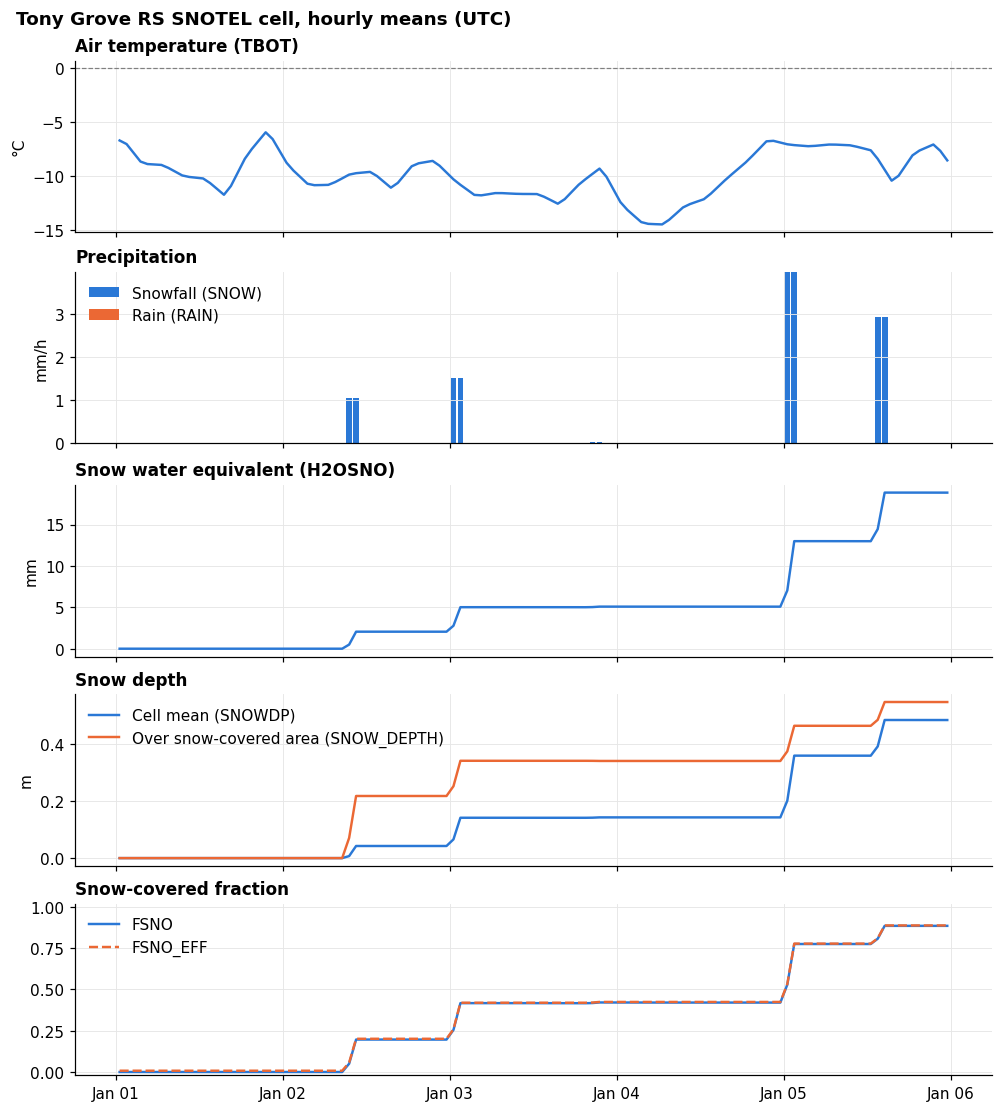

In [10]:
s = site_cell
fig, axs = plt.subplots(5, 1, figsize=(9, 10), sharex=True, layout="constrained")

ax = axs[0]
ax.plot(s.time, s.TBOT, color=C1)
ax.axhline(0, color="0.5", lw=0.8, ls="--")
ax.set_ylabel("°C"); ax.set_title("Air temperature (TBOT)")

ax = axs[1]
w = np.timedelta64(50, "m")
ax.bar(s.time, s.SNOW, width=w, color=C1, label="Snowfall (SNOW)")
ax.bar(s.time, s.RAIN, width=w, bottom=s.SNOW, color=C2, label="Rain (RAIN)")
ax.set_ylabel("mm/h"); ax.set_title("Precipitation"); ax.legend(frameon=False)

ax = axs[2]
ax.plot(s.time, s.H2OSNO, color=C1)
ax.set_ylabel("mm"); ax.set_title("Snow water equivalent (H2OSNO)")

ax = axs[3]
ax.plot(s.time, s.SNOWDP, color=C1, label="Cell mean (SNOWDP)")
ax.plot(s.time, s.SNOW_DEPTH, color=C2, label="Over snow-covered area (SNOW_DEPTH)")
ax.set_ylabel("m"); ax.set_title("Snow depth"); ax.legend(frameon=False)

ax = axs[4]
ax.plot(s.time, s.FSNO, color=C1, label="FSNO")
ax.plot(s.time, s.FSNO_EFF, color=C2, ls="--", label="FSNO_EFF")
ax.set_ylim(-0.02, 1.02); ax.set_title("Snow-covered fraction"); ax.legend(frameon=False)

axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.suptitle(f"{SITE_NAME} cell, hourly means (UTC)", x=0.01, ha="left", fontweight="bold")

### Check: bulk snow density

`H2OSNO / SNOWDP` is the bulk density of the snowpack (kg/m³, since 1 mm SWE = 1 kg/m²).
In this run new snow falls at `bifall ≥ 50 kg/m³` (`CanopyHydrologyMod.F90`: 50 below
−15 °C, rising with temperature), and compaction only makes snow denser. So bulk
density should never be below 50 kg/m³.

If it is, a likely cause is in the SL12 depth update, `update_snow_depth_from_fsca` in
`SnowCoverFractionMod.F90`. When new snow falls, `snow_depth` (depth over the
snow-covered area) increases by `newsnow / (bifall · frac_sno)` using the *new*, larger
fSCA. Then ELM sets `snowdp = snow_depth · frac_sno_eff`. So the snow that was already
there keeps its depth while it is spread over the larger area, and the cell-mean snow
volume grows by more than the new snow alone.

Bulk density, all cells/hours with > 2 cm snow: min 13, median 39, max 113 kg/m³


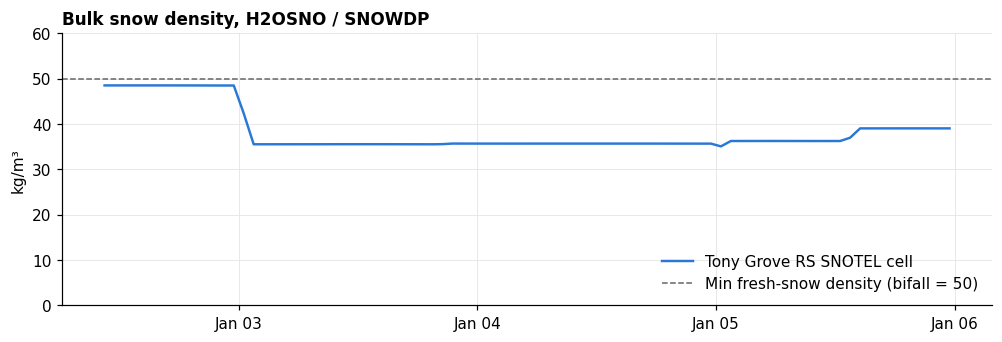

In [11]:
rho = (hourly.H2OSNO / hourly.SNOWDP).where(hourly.SNOWDP > 0.02)   # kg/m3, cells with > 2 cm snow
print(f"Bulk density, all cells/hours with > 2 cm snow: "
      f"min {float(rho.min()):.0f}, median {float(rho.median()):.0f}, max {float(rho.max()):.0f} kg/m³")

fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(s.time, rho.sel(site, method="nearest"), color=C1, label=f"{SITE_NAME} cell")
ax.axhline(50, color="0.4", lw=1, ls="--", label="Min fresh-snow density (bifall = 50)")
ax.set_ylim(0, 60); ax.set_ylabel("kg/m³"); ax.legend(frameon=False, loc="lower right")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.set_title("Bulk snow density, H2OSNO / SNOWDP")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

## Surface energy balance at the site

Top: incoming solar (`FSDS`, from the forcing), reflected solar (`FSR`) and absorbed
solar (`FSA = FSDS − FSR`).

Middle: the turbulent fluxes, sensible (`FSH`) and latent (`EFLX_LH_TOT`), positive
upward.

Bottom: broadband surface albedo `FSR / FSDS`, during daylight only (FSDS > 20 W/m²).
With SNICAR on (`use_snicar_ad = .true.`), snow albedo depends on grain size
(`SNORDSL`), so fresh, fine-grained snow shows up as high albedo.

Times are UTC; local solar noon at Tony Grove is about 19:30 UTC.

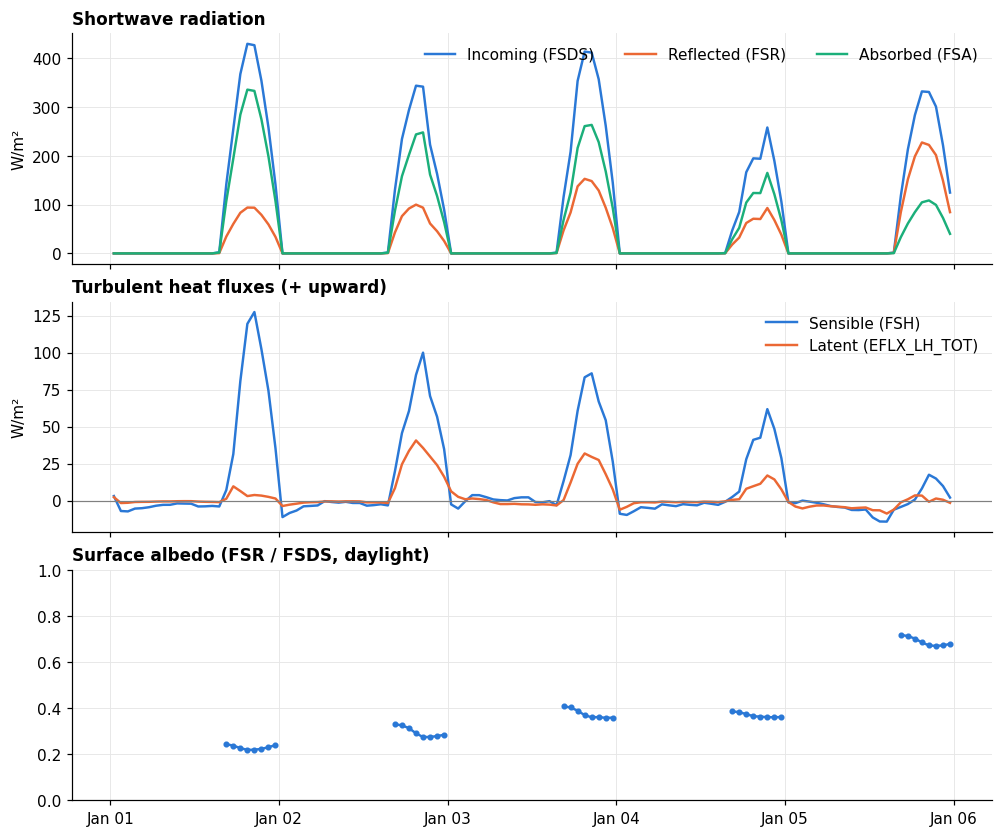

In [12]:
fig, axs = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True, layout="constrained")

ax = axs[0]
ax.plot(s.time, s.FSDS, color=C1, label="Incoming (FSDS)")
ax.plot(s.time, s.FSR, color=C2, label="Reflected (FSR)")
ax.plot(s.time, s.FSA, color=C3, label="Absorbed (FSA)")
ax.set_ylabel("W/m²"); ax.set_title("Shortwave radiation"); ax.legend(frameon=False, ncols=3)

ax = axs[1]
ax.plot(s.time, s.FSH, color=C1, label="Sensible (FSH)")
ax.plot(s.time, s.EFLX_LH_TOT, color=C2, label="Latent (EFLX_LH_TOT)")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylabel("W/m²"); ax.set_title("Turbulent heat fluxes (+ upward)"); ax.legend(frameon=False)

ax = axs[2]
albedo = (s.FSR / s.FSDS).where(s.FSDS > 20)
ax.plot(s.time, albedo, color=C1, marker="o", ms=3)
ax.set_ylim(0, 1); ax.set_title("Surface albedo (FSR / FSDS, daylight)")

axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

## Snow-layer properties at the site

Top-layer snow temperature (`SNOTTOPL`) next to the ground/surface temperature (`TG`), and
top-layer grain radius (`SNORDSL`). The gaps are hours with no snow layer.
Fresh snow starts at a small grain radius (SNICAR's default fresh-snow radius) and
the grains grow as the snow ages.

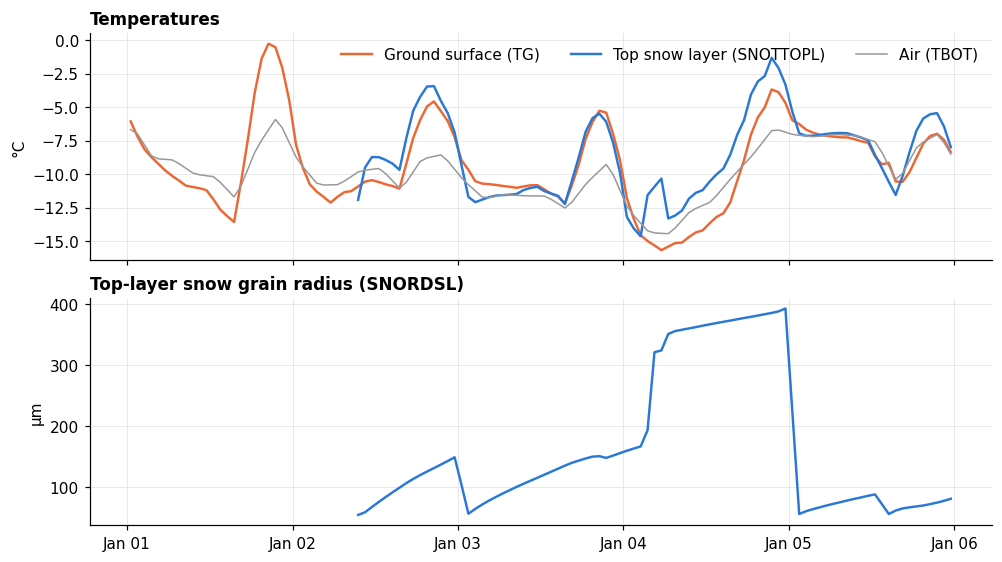

In [13]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")

ax = axs[0]
ax.plot(s.time, s.TG, color=C2, label="Ground surface (TG)")
ax.plot(s.time, s.SNOTTOPL, color=C1, label="Top snow layer (SNOTTOPL)")
ax.plot(s.time, s.TBOT, color="0.6", lw=1, label="Air (TBOT)")
ax.set_ylabel("°C"); ax.set_title("Temperatures"); ax.legend(frameon=False, ncols=3)

ax = axs[1]
ax.plot(s.time, s.SNORDSL, color=C1)
ax.set_ylabel("μm"); ax.set_title("Top-layer snow grain radius (SNORDSL)")

axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

## Daily maps across the domain

Daily-mean SWE and snow-covered fraction for each of the 5 days (from the h0 tape).
Each row shares one color scale.

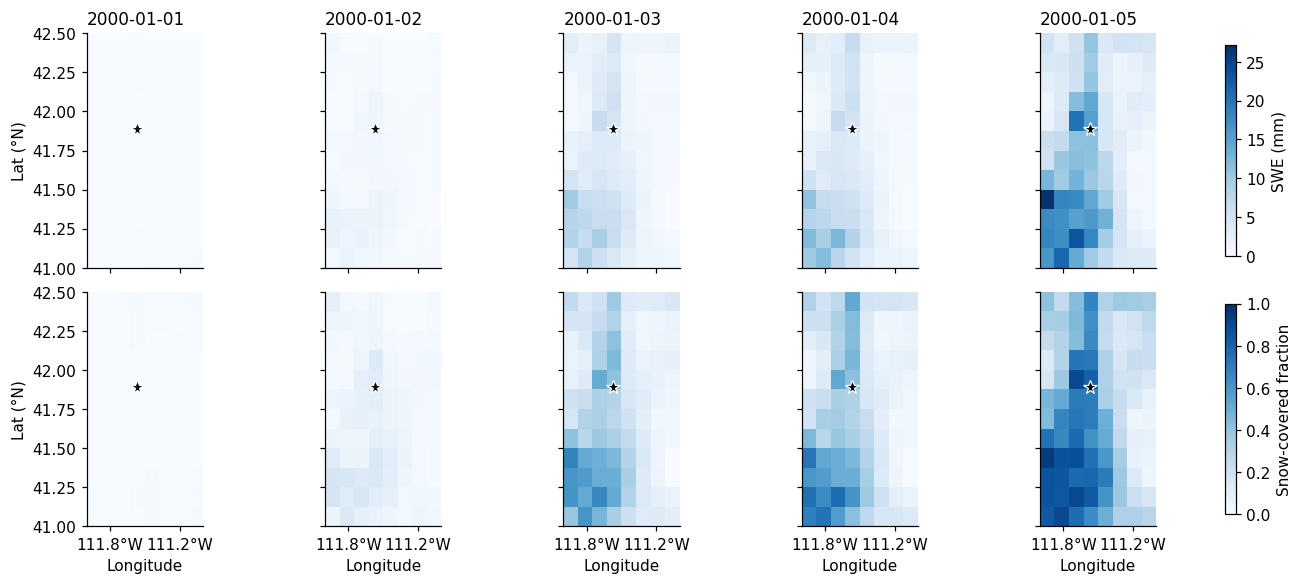

In [14]:
fig, axs = plt.subplots(2, daily.sizes["time"], figsize=(12, 5.2), sharex=True, sharey=True,
                        layout="constrained")
rows = [("H2OSNO", "SWE (mm)", "Blues", 0, float(daily.H2OSNO.max())),
        ("FSNO", "Snow-covered fraction", "Blues", 0, 1)]
for r, (var, label, cmap, vmin, vmax) in enumerate(rows):
    for i in range(daily.sizes["time"]):
        ax = axs[r, i]
        d = daily[var].isel(time=i)
        im = ax.pcolormesh(daily.lon, daily.lat, d, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.plot(SITE_LON, SITE_LAT, marker="*", ms=9, color="k", mec="w", mew=0.8)
        ax.set_aspect(1 / np.cos(np.deg2rad(SITE_LAT)))
        ax.xaxis.set_major_locator(plt.FixedLocator([-111.8, -111.2]))
        ax.xaxis.set_major_formatter(lambda v, _: f"{-v:.1f}°W")
        ax.grid(False)
        if r == 0:
            ax.set_title(str(d.time.values)[:10], fontweight="normal")
    fig.colorbar(im, ax=axs[r, :], label=label, shrink=0.9)
for ax in axs[:, 0]:
    ax.set_ylabel("Lat (°N)")
for ax in axs[-1, :]:
    ax.set_xlabel("Longitude")

## Domain-mean daily budget

Daily snowfall, rain, melt and runoff averaged over all 96 cells (all cells have about
the same area), with domain-mean SWE. A check on the water balance: SWE grows by
roughly snowfall minus melt (minus sublimation, not saved here).

                     SNOW  RAIN  QSNOMELT  QRUNOFF  H2OSNO
time                                                      
2000-01-01 12:00:00  0.04   0.0      0.03    -0.03    0.03
2000-01-02 12:00:00  1.72   0.0      0.05    -0.02    0.60
2000-01-03 12:00:00  1.65   0.0      0.02    -0.02    2.73
2000-01-04 12:00:00  0.00   0.0      0.09    -0.02    3.18
2000-01-05 12:00:00  6.72   0.0      0.06     0.02    7.42


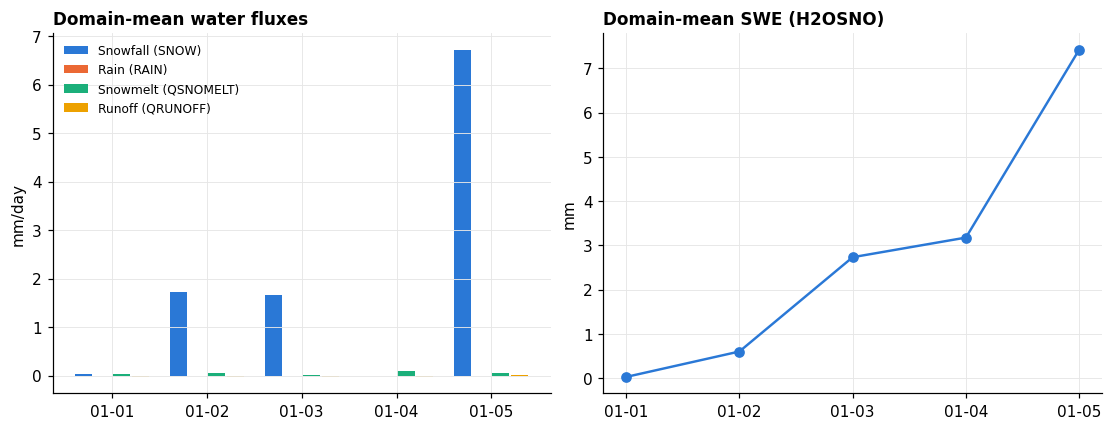

In [15]:
dm = daily.mean(["lat", "lon"])
days = [str(t)[5:10] for t in dm.time.values]
x = np.arange(len(days))
bw = 0.2

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
ax = axs[0]
for j, (v, c, lab) in enumerate([("SNOW", C1, "Snowfall"), ("RAIN", C2, "Rain"),
                                  ("QSNOMELT", C3, "Snowmelt"), ("QRUNOFF", "#eda100", "Runoff")]):
    ax.bar(x + (j - 1.5) * bw, dm[v], width=bw * 0.9, color=c, label=f"{lab} ({v})")
ax.set_xticks(x, days); ax.set_ylabel("mm/day")
ax.set_title("Domain-mean water fluxes"); ax.legend(frameon=False, fontsize=8)

ax = axs[1]
ax.plot(x, dm.H2OSNO, color=C1, marker="o")
ax.set_xticks(x, days); ax.set_ylabel("mm")
ax.set_title("Domain-mean SWE (H2OSNO)")

print(dm[["SNOW", "RAIN", "QSNOMELT", "QRUNOFF", "H2OSNO"]].to_dataframe().round(2))

## Snow cover vs. snow depth (the fSCA curve)

Every cell and hour as one point: snow-covered fraction against grid-cell mean snow depth.
SL12 tracks fSCA through *changes* in SWE, not SWE or depth itself:
- new snow adds to the existing fraction:
  `frac_sno = 1 − (1 − tanh(0.1·newsnow))·(1 − frac_sno)`, with `newsnow` in mm
- melt depletes it along an arccos curve of `SWE / swe_max_eff`, with shape
  parameter `n_melt` that comes from the cell's subgrid elevation variability

Snow depth is then derived from fSCA. So the points don't fall on one curve. The
code is `fsca_SL12_update` in `components/elm/src/biogeophys/SnowCoverFractionMod.F90`
on the `ez/fsca` branch.

Only 5 days of accumulation from a cold start, so this mostly shows the
accumulation branch.

Text(0.0, 1.0, 'FSNO vs SNOWDP, all cells, hourly')

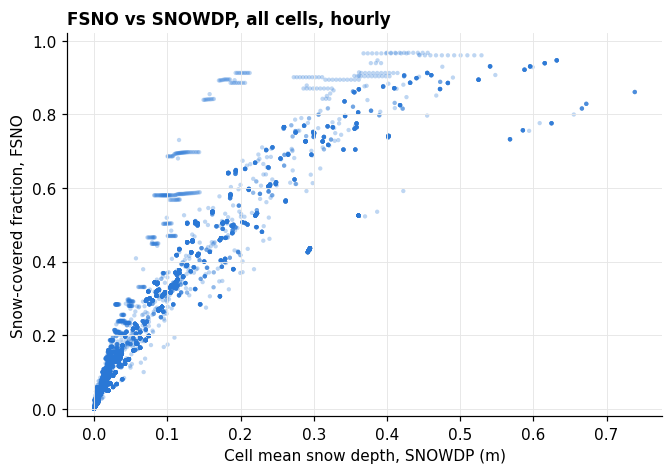

In [16]:
fig, ax = plt.subplots(figsize=(6, 4.2), layout="constrained")
ax.scatter(hourly.SNOWDP.values.ravel(), hourly.FSNO.values.ravel(),
           s=8, alpha=0.3, color=C1, edgecolors="none")
ax.set_xlabel("Cell mean snow depth, SNOWDP (m)")
ax.set_ylabel("Snow-covered fraction, FSNO")
ax.set_ylim(-0.02, 1.02)
ax.set_title("FSNO vs SNOWDP, all cells, hourly")